# Proyecto Análisis de Noticias Falsas

**Integrantes:**
- [César Mauricio Ocampo Ramírez](mailto:czrokmpo@gmail.com)
- [Rebecca Shaday Castillo Ortega](mailto:rebeccashaday@gmail.com)
- [Kevin Vargas Flores](mailto:kevinvargasflores505@gmail.com)


## Descripción
Comparar un modelo generativo (Bayes ingenuo) con uno discriminativo (regresión logística, equivalente a un modelo de máxima entropía) en un problema desbalanceado, y decidir el umbral de clasificación en función del costo de los errores.



## Contribuciones

| Etapa | Integrante | Rol | Quién lo revisó |
| --- | --- | --- | --- |
| 1 | César | Formalización en papel | Rebecca |
| 1 | Rebecca | Implementación | Kevin |
| 1 | Kevin | Evaluación (métricas y control) | César |
---
| Etapa | Integrante | Rol | Quién lo revisó |
| --- | --- | --- | --- |
| 2 |  | Formalización en papel | Rebecca |
| 2 | Kevin | Implementación | Kevin |
| 2 |  | Evaluación (métricas y control) | César |
---
| Etapa | Integrante | Rol | Quién lo revisó |
| --- | --- | --- | --- |
| 3 |  | Formalización en papel | Rebecca |
| 3 | Kevin | Implementación | Kevin |
| 3 |  | Evaluación (métricas y control) | César |

# Etapa 1: Análisis, representación y baseline


## Dataset

In [30]:
#@title librerías etapa 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer as countvectorizer
from sklearn.naive_bayes import MultinomialNB as multinomialnb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)
from sklearn.metrics import roc_curve, auc

seed = 98
np.random.seed(seed)

# Importación del dataset

data = 'https://github.com/kao05/SpamAnalysis-TextMining/raw/main/Data/New/dataset_Notices.csv'

df = pd.read_csv(data)

print(df.head())

                                               title  \
0  SAY WHAT?! Muslim Women Can Now Cover Their Fa...   
1  WATCH: CNN DOES SEGMENT From Bunker In Hawaii,...   
2         Britain agrees to set EU 'Exit Day' in law   
3  ACTOR ROB LOWE Blasts Greedy Socialist Bernie ...   
4  WIKILEAKS REMINDS THE WORLD: “Obama has a hist...   

                                                text    subject  \
0  Soooo ah, what s the point of the picture?Not ...   politics   
1  CNN host Erin Burnett started out her segment ...  left-news   
2  LONDON (Reuters) - Britain s government said o...  worldnews   
3  It s always fun when Hollywood shows a conserv...  left-news   
4  Wikileaks founder Julian Assange reminded us i...   politics   

                date label  
0       Sep 11, 2015  Fake  
1       Aug 10, 2017  Fake  
2  November 9, 2017   Real  
3       Jan 27, 2016  Fake  
4        Mar 5, 2017  Fake  


In [2]:
df.shape

(44898, 5)

## Exploración del Corpus

label
Fake    23481
Real    21417
Name: count, dtype: int64
label
Fake    0.523
Real    0.477
Name: count, dtype: float64
nulos: 0


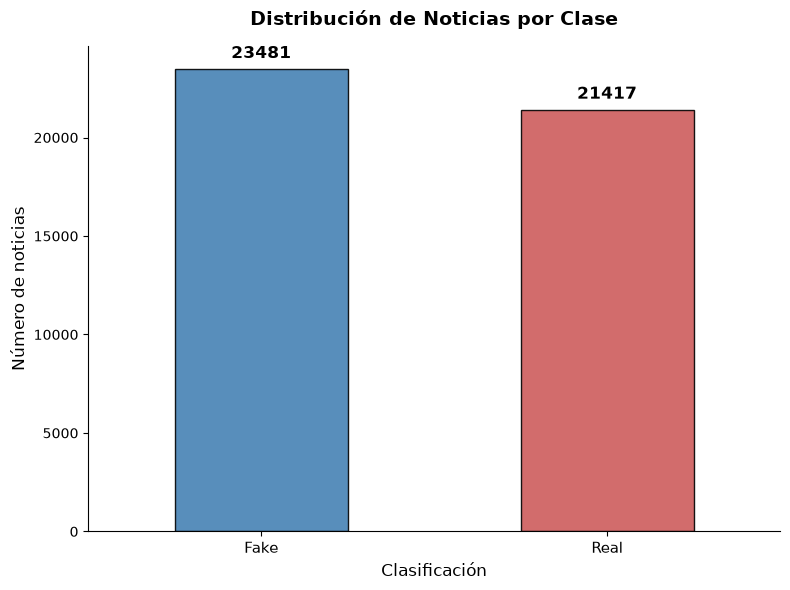

In [3]:
#@title desbalance, nulos y duplicados
conteo = df['label'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

print('nulos:', df.isnull().sum().sum())
#print('noticias duplicadas:', df.duplicated(subset='text').sum())

plt.figure(figsize=(8, 6))
# Almacenar el gráfico en la variable 'ax' para poder manipularlo
ax = conteo.plot(kind='bar', color=['steelblue', 'indianred'], alpha=0.9, edgecolor='black')

# Agregar la cantidad de datos sobre cada barra
# ax.containers[0] contiene las barras; padding separa el número de la barra
ax.bar_label(ax.containers[0], fmt='%d', padding=5, fontsize=12, fontweight='bold')

# Mejorar los títulos y etiquetas
plt.title('Distribución de Noticias por Clase', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('Número de noticias', fontsize=12)
plt.xlabel('Clasificación', fontsize=12)

# Poner las etiquetas del eje X en horizontal para mejor lectura
plt.xticks(rotation=0, fontsize=11)

# Quitar los bordes superior y derecho para un diseño más limpio (estilo minimalista)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Ajustar automáticamente los márgenes
plt.tight_layout()

# Mostrar el gráfico
plt.show()

tamaño después de quitar duplicados: (38646, 6)
proporción de Noticias Falsas: 0.4517
label
Real    21191
Fake    17455
Name: count, dtype: int64
label
Real    0.548
Fake    0.452
Name: count, dtype: float64


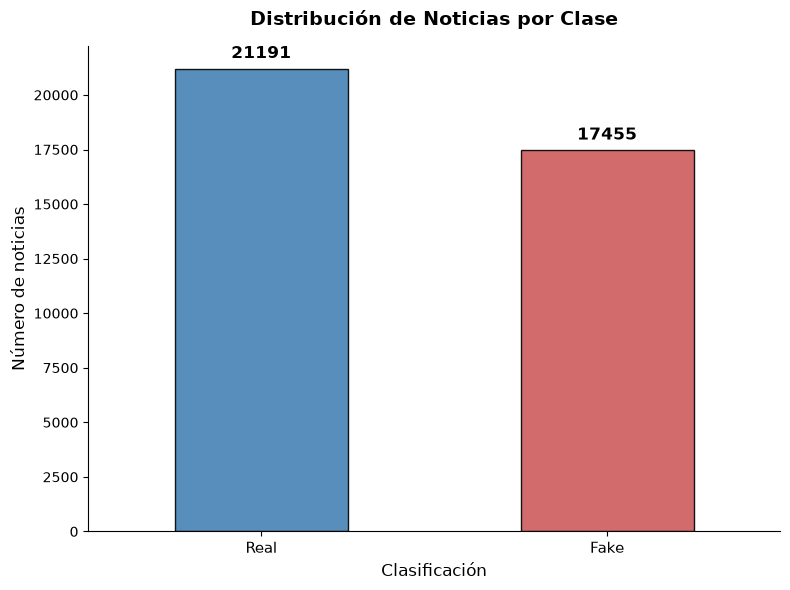

In [4]:
#@title quitar duplicados antes de dividir y etiqueta numérica
# Para las noticias falsas cuando verificamos datos duplicados en esta parte nos estamos basando unicamente en texto, no en las otras columnas
df = df.drop_duplicates(subset='text', keep='first').reset_index(drop=True)
df['y'] = (df['label'] == 'Fake').astype(int)

print('tamaño después de quitar duplicados:', df.shape)
print('proporción de Noticias Falsas:', round(df['y'].mean(), 4))

conteoafter = df['label'].value_counts()
print(conteoafter)
print((conteoafter / len(df)).round(3))

plt.figure(figsize=(8, 6))
# Almacenar el gráfico en la variable 'ax' para poder manipularlo
ax = conteoafter.plot(kind='bar', color=['steelblue', 'indianred'], alpha=0.9, edgecolor='black')

# Agregar la cantidad de datos sobre cada barra
# ax.containers[0] contiene las barras; padding separa el número de la barra
ax.bar_label(ax.containers[0], fmt='%d', padding=5, fontsize=12, fontweight='bold')

# Mejorar los títulos y etiquetas
plt.title('Distribución de Noticias por Clase', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('Número de noticias', fontsize=12)
plt.xlabel('Clasificación', fontsize=12)

# Poner las etiquetas del eje X en horizontal para mejor lectura
plt.xticks(rotation=0, fontsize=11)

# Quitar los bordes superior y derecho para un diseño más limpio (estilo minimalista)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Ajustar automáticamente los márgenes
plt.tight_layout()

# Mostrar el gráfico
plt.show()

label                   Fake      Real
n_caracteres count  17455.00  21191.00
             mean    2549.81   2378.53
             std     2201.33   1683.78
             min        1.00    152.00
             25%     1648.50    906.50
             50%     2235.00   2216.00
             75%     3005.50   3226.50
             max    51794.00  29781.00
n_palabras   count  17455.00  21191.00
             mean     425.26    384.83
             std      355.20    273.78
             min        0.00     22.00
             25%      277.00    147.00
             50%      376.00    359.00
             75%      503.00    523.00
             max     8135.00   5172.00


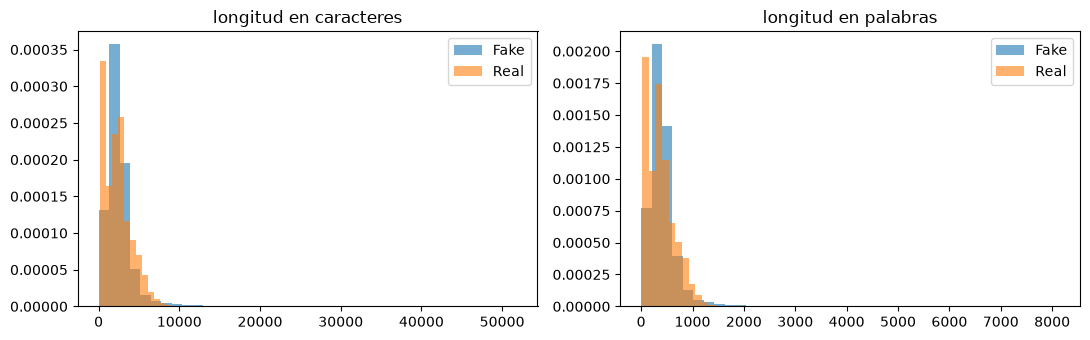

In [6]:
#@title logitudes por clase
df['n_caracteres'] = df['text'].str.len()
df['n_palabras'] = df['text'].str.split().str.len()

print(df.groupby('label')[['n_caracteres', 'n_palabras']].describe().T.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))

for etiqueta, grupo in df.groupby('label'):
    ejes[0].hist(
        grupo['n_caracteres'],
        bins=40, alpha=0.6, density=True, label=etiqueta
    )
    ejes[1].hist(
        grupo['n_palabras'],
        bins=40, alpha=0.6, density=True, label=etiqueta
    )

ejes[0].set_title('longitud en caracteres')
ejes[1].set_title('longitud en palabras')
ejes[0].legend()
ejes[1].legend()

plt.tight_layout()
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


tamaño del vocabulario (corpus completo): 122341

Fake -> [('the', 395297), ('to', 218306), ('of', 172302), ('and', 168268), ('a', 160348), ('in', 124561), ('that', 117892), ('s', 107041), ('is', 86209), ('for', 69631), ('trump', 68119), ('it', 65230), ('he', 64536), ('on', 62069), ('was', 49569)]

Real -> [('the', 476245), ('to', 242635), ('of', 202728), ('a', 196029), ('and', 179769), ('in', 179264), ('s', 139667), ('on', 107148), ('said', 97814), ('that', 87182), ('for', 78908), ('is', 54797), ('trump', 54073), ('with', 53844), ('he', 53674)]


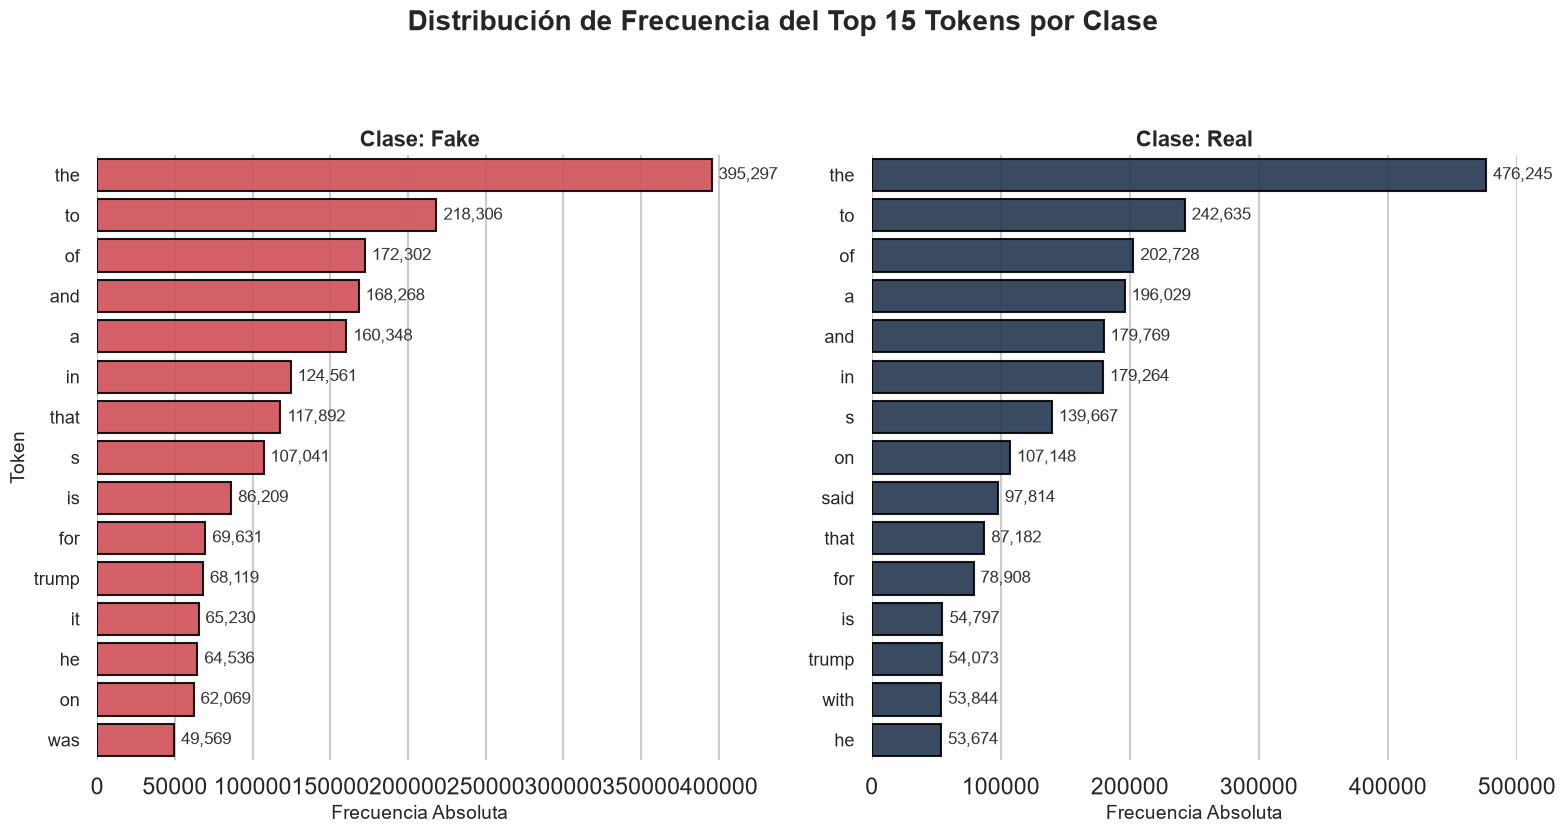

In [7]:
# @title exploración del vocabulario por clase
token_patron = r"[a-z0-9£$]+|!"

vec_explora = countvectorizer(
    lowercase=True,
    token_pattern=token_patron
)

x_explora = vec_explora.fit_transform(df['text'])
vocab_explora = np.array(vec_explora.get_feature_names_out())

print('tamaño del vocabulario (corpus completo):', len(vocab_explora))

for etiqueta in ['Fake', 'Real']:
    mascara = (df['label'] == etiqueta).values
    frec = np.asarray(x_explora[mascara].sum(axis=0)).ravel()
    top = np.argsort(frec)[::-1][:15]

    print(
        '\n' + etiqueta + ' ->',
        list(zip(vocab_explora[top], frec[top].tolist()))
    )
#Ploteo
#---------
# 1. Transformación de los tensores racheles a un DataFrame estructurado para Seaborn
datos_grafica = []

for etiqueta in ['Fake', 'Real']:
    mascara = (df['label'] == etiqueta).values
    frec = np.asarray(x_explora[mascara].sum(axis=0)).ravel()
    top = np.argsort(frec)[::-1][:15] # Top 15 índices con mayor masa de frecuencia
    
    for palabra, frecuencia in zip(vocab_explora[top], frec[top]):
        datos_grafica.append({
            'Clase': etiqueta,
            'Token': palabra,
            'Frecuencia Absoluta': frecuencia
        })

df_frecuencias = pd.DataFrame(datos_grafica)

# 2. Configuración estética rigurosa orientada a presentaciones (estilo académico/profesional)
sns.set_theme(style="whitegrid", context="talk")
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=False)
fig.suptitle('Distribución de Frecuencia del Top 15 Tokens por Clase', fontsize=20, fontweight='bold', y=1.05)

# Paleta divergente con contraste semántico ('Fake' = Rojo/Alerta, 'Real' = Azul/Institucional)
colores = {'Fake': '#E63946', 'Real': '#1D3557'}

# 3. Renderizado iterativo de las distribuciones
for i, etiqueta in enumerate(['Fake', 'Real']):
    ax = axes[i]
    df_subset = df_frecuencias[df_frecuencias['Clase'] == etiqueta]
    
    # Generación de la gráfica base
    sns.barplot(
        data=df_subset,
        x='Frecuencia Absoluta',
        y='Token',
        ax=ax,
        color=colores[etiqueta],
        edgecolor='black',
        alpha=0.9
    )
    
    # Formateo de ejes y meta-información
    ax.set_title(f'Clase: {etiqueta}', fontsize=16, fontweight='bold')
    ax.set_xlabel('Frecuencia Absoluta', fontsize=14)
    ax.set_ylabel('Token' if i == 0 else '', fontsize=14)
    ax.tick_params(axis='y', labelsize=13)
    
    # Inyección de las magnitudes exactas sobre las barras (Precisión cuantitativa)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_width()):,}", 
                    (p.get_width(), p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', 
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=12, fontweight='medium', color='#333333')

# Optimización del espacio topológico de la figura
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## Train, Dev y Test
Implementada con muestreo estratificado, proporciones 70/15/15 y semilla fija.

        Real   Fake  proporcion Fake
train  14834  12218           0.4516
dev     3178   2619           0.4518
test    3179   2618           0.4516


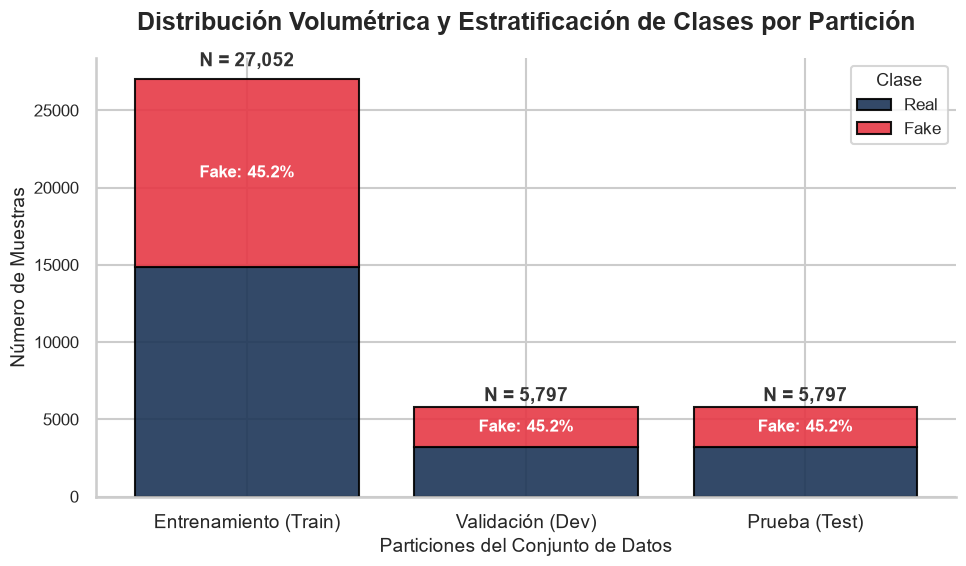

In [10]:
x_texto = df['text']
y = df['y']

x_train_txt, x_temp_txt, y_train, y_temp = train_test_split( x_texto, y, test_size=0.30, stratify=y, random_state=seed)

x_dev_txt, x_test_txt, y_dev, y_test = train_test_split( x_temp_txt, y_temp, test_size=0.50, stratify=y_temp, random_state=seed)

resumen = pd.DataFrame({
    'Real': [len(y_train) - y_train.sum(), len(y_dev) - y_dev.sum(), len(y_test) - y_test.sum()],
    'Fake': [y_train.sum(), y_dev.sum(), y_test.sum()],
    'proporcion Fake': [y_train.mean(), y_dev.mean(), y_test.mean()]
}, index=['train', 'dev', 'test']).round(4)
print(resumen)

#Ploteo
#------
# Sustituye estas variables por las tuyas en tu entorno de ejecución
datos_separacion = {
    'Partición': ['Entrenamiento (Train)', 'Validación (Dev)', 'Prueba (Test)'],
    'Real': [len(y_train) - y_train.sum(), len(y_dev) - y_dev.sum(), len(y_test) - y_test.sum()],
    'Fake': [y_train.sum(), y_dev.sum(), y_test.sum()]
}

df_plot = pd.DataFrame(datos_separacion).set_index('Partición')

# 2. Configuración estética orientada a presentación académica
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(10, 6))

# Paleta coherente con la gráfica anterior
color_real = '#1D3557' # Azul institucional
color_fake = '#E63946' # Rojo alerta

# 3. Generación del Gráfico de Barras Apiladas
# Ploteo de la base ('Real')
ax.bar(df_plot.index, df_plot['Real'], label='Real', color=color_real, edgecolor='black', alpha=0.9)
# Ploteo de la cima ('Fake') sobre la base ('Real')
ax.bar(df_plot.index, df_plot['Fake'], bottom=df_plot['Real'], label='Fake', color=color_fake, edgecolor='black', alpha=0.9)

# 4. Anotaciones de rigor (Volumen total y Porcentaje de estratificación)
for i, particion in enumerate(df_plot.index):
    total = df_plot.loc[particion, 'Real'] + df_plot.loc[particion, 'Fake']
    fake_count = df_plot.loc[particion, 'Fake']
    proporcion_fake = (fake_count / total) * 100
    
    # Anotación del volumen total en la parte superior de la barra
    ax.text(i, total + (total * 0.02), f'N = {int(total):,}', 
            ha='center', va='bottom', fontsize=14, fontweight='bold', color='#333333')
    
    # Anotación demostrativa de la estratificación (dentro de la barra Fake)
    ax.text(i, total - (fake_count / 2), f'Fake: {proporcion_fake:.1f}%', 
            ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# 5. Formateo de ejes y metadatos
ax.set_title('Distribución Volumétrica y Estratificación de Clases por Partición', fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Número de Muestras', fontsize=14)
ax.set_xlabel('Particiones del Conjunto de Datos', fontsize=14)
ax.tick_params(axis='y', labelsize=12)
ax.tick_params(axis='x', labelsize=14)
ax.legend(title='Clase', title_fontsize='13', fontsize='12', loc='upper right')

# Optimización espacial
sns.despine()
plt.tight_layout()
plt.show()

## Baseline

tipo de matriz: <class 'scipy.sparse._csr.csr_matrix'>
forma de x_train: (27052, 101945)
densidad (fracción de entradas distintas de cero): 0.0021


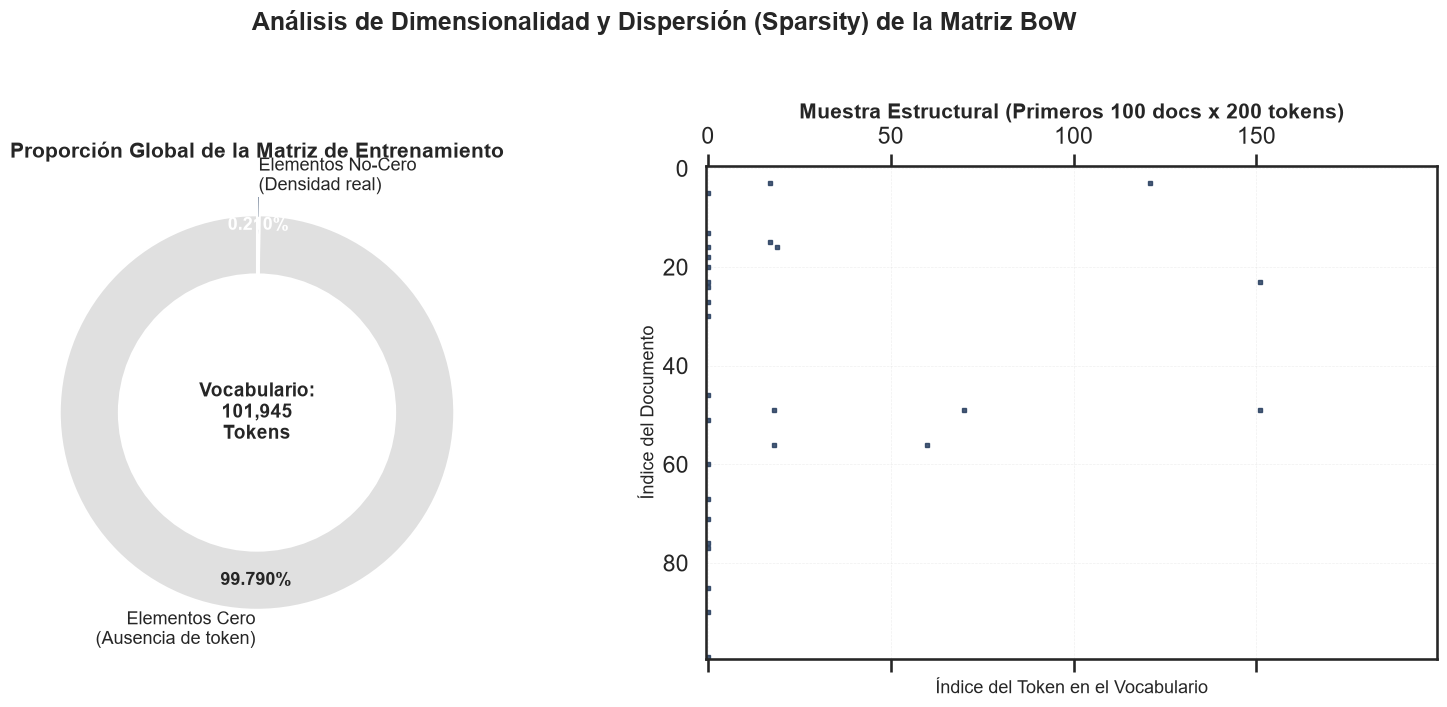

In [12]:
#@title representación de bolsa de palabras y vocabulario solo con train
vec = countvectorizer(lowercase=True, token_pattern=token_patron)

x_train = vec.fit_transform(x_train_txt)#el vocab se aprende solo con train
x_dev = vec.transform(x_dev_txt)
x_test = vec.transform(x_test_txt)

densidad = x_train.nnz / (x_train.shape[0] * x_train.shape[1])
print('tipo de matriz:', type(x_train))
print('forma de x_train:', x_train.shape)
print('densidad (fracción de entradas distintas de cero):', round(densidad, 5))


#Ploteo
#----------
# 1. Extracción de métricas de dimensionalidad basadas en tus variables
n_filas, n_columnas = x_train.shape
total_elementos = n_filas * n_columnas
no_ceros = x_train.nnz
ceros = total_elementos - no_ceros

# Calculamos el porcentaje para el gráfico
porcentaje_ceros = (ceros / total_elementos) * 100
porcentaje_densidad = (no_ceros / total_elementos) * 100

# 2. Configuración estética rigurosa orientada a presentación
sns.set_theme(style="white", context="talk")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Análisis de Dimensionalidad y Dispersión (Sparsity) de la Matriz BoW', 
             fontsize=18, fontweight='bold', y=1.02)

color_cero = '#E0E0E0'  # Gris tenue para el "vacío" (ceros)
color_densidad = '#1D3557'  # Azul institucional para la información real (no-ceros)

# --- Subplot 1: Gráfico de Proporción (Donut Chart) ---
ax1 = axes[0]
wedges, texts, autotexts = ax1.pie(
    [ceros, no_ceros], 
    labels=['Elementos Cero\n(Ausencia de token)', 'Elementos No-Cero\n(Densidad real)'], 
    colors=[color_cero, color_densidad],
    autopct='%1.3f%%', # 3 decimales para apreciar la densidad diminuta típica del PLN
    startangle=90,
    pctdistance=0.85,
    explode=(0, 0.1),
    textprops={'fontsize': 13}
)

# Estilización de los textos del gráfico circular
for autotext in autotexts:
    autotext.set_fontweight('bold')
autotexts[1].set_color('white') # Contraste para el azul oscuro

# Convertir a Dona para estética moderna
centro_circulo = plt.Circle((0,0), 0.70, fc='white')
ax1.add_artist(centro_circulo)
ax1.set_title('Proporción Global de la Matriz de Entrenamiento', fontsize=15, fontweight='bold')
ax1.text(0, 0, f'Vocabulario:\n{n_columnas:,}\nTokens', ha='center', va='center', fontsize=14, fontweight='bold')

# --- Subplot 2: Representación Espacial (Spy Plot) ---
ax2 = axes[1]
# Extraemos una muestra representativa (ej. 100 documentos x 200 tokens) para evitar colapso visual
# Aseguramos no exceder el tamaño real si es un dataset pequeño
muestra_filas = min(100, n_filas)
muestra_cols = min(200, n_columnas)

# Extracción de la sub-matriz densa para la visualización
sub_matriz = x_train[:muestra_filas, :muestra_cols].toarray()

# plt.spy grafica los valores distintos de cero como puntos negros (u otro color)
ax2.spy(sub_matriz, markersize=3, color=color_densidad, aspect='auto', alpha=0.8)

ax2.set_title(f'Muestra Estructural (Primeros {muestra_filas} docs x {muestra_cols} tokens)', 
              fontsize=15, fontweight='bold')
ax2.set_xlabel('Índice del Token en el Vocabulario', fontsize=13)
ax2.set_ylabel('Índice del Documento', fontsize=13)

# Grid sutil para ubicar coordenadas en el spy plot
ax2.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.3)

plt.tight_layout()
plt.show()

Solo Fake: 8740 | Solo Real: 7075 | Compartidas: 17509
Jaccard (vocabulario): 0.525
Similitud coseno entre clases: 0.972


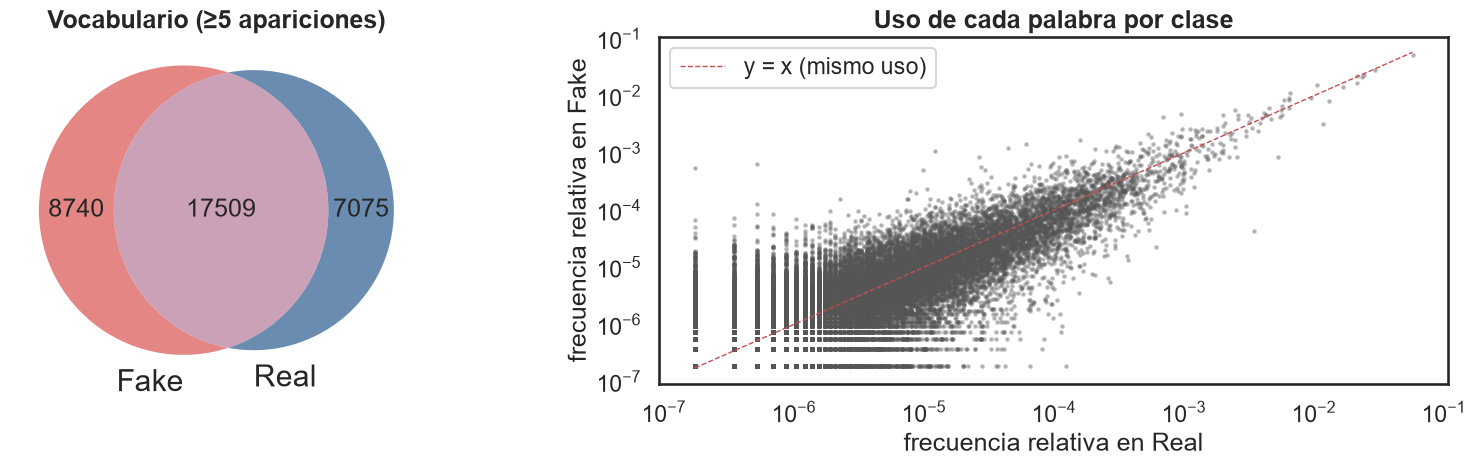

In [14]:
#@title traslape de vocabulario entre clases (Fake vs Real)
vocab = np.array(vec.get_feature_names_out())
mask_fake = (y_train.values == 1)
mask_real = (y_train.values == 0)

frec_fake = np.asarray(x_train[mask_fake].sum(axis=0)).ravel()
frec_real = np.asarray(x_train[mask_real].sum(axis=0)).ravel()

# umbral mínimo para ignorar palabras raras (typos, nombres únicos, etc.)
min_frec = 5
en_fake = frec_fake >= min_frec
en_real = frec_real >= min_frec

solo_fake = (en_fake & ~en_real).sum()
solo_real = (~en_fake & en_real).sum()
ambas = (en_fake & en_real).sum()

print(f"Solo Fake: {solo_fake} | Solo Real: {solo_real} | Compartidas: {ambas}")
print(f"Jaccard (vocabulario): {ambas / (solo_fake + solo_real + ambas):.3f}")

# similitud coseno entre los perfiles de frecuencia de cada clase
coseno = (frec_fake @ frec_real) / (np.linalg.norm(frec_fake) * np.linalg.norm(frec_real))
print(f"Similitud coseno entre clases: {coseno:.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(17, 5))

# 1) Diagrama de Venn del vocabulario
venn2(subsets=(solo_fake, solo_real, ambas), set_labels=('Fake', 'Real'),
      set_colors=('#d9534f', '#2b5c8f'), alpha=0.7, ax=ejes[0])
ejes[0].set_title(f'Vocabulario (≥{min_frec} apariciones)', fontweight='bold')

# 2) Scatter de frecuencias relativas (log-log). Cerca de la diagonal = palabra compartida
p_fake = frec_fake / frec_fake.sum()
p_real = frec_real / frec_real.sum()
ambas_mask = (frec_fake > 0) & (frec_real > 0)
ejes[1].scatter(p_real[ambas_mask], p_fake[ambas_mask], s=4, alpha=0.3, color='#555')
lim = [min(p_fake[ambas_mask].min(), p_real[ambas_mask].min()),
       max(p_fake[ambas_mask].max(), p_real[ambas_mask].max())]
ejes[1].plot(lim, lim, 'r--', lw=1, label='y = x (mismo uso)')
ejes[1].set_xscale('log'); ejes[1].set_yscale('log')
ejes[1].set_xlabel('frecuencia relativa en Real')
ejes[1].set_ylabel('frecuencia relativa en Fake')
ejes[1].set_title('Uso de cada palabra por clase', fontweight='bold')
ejes[1].legend()

# 3) Histograma de |log-razón|: qué tan discriminativas son las palabras
#idx = np.where(frec_train_total := (frec_fake + frec_real) >= min_frec)[0]
#log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
#ejes[2].hist(log_razon[idx], bins=60, color='#7a5fa0', edgecolor='black', alpha=0.85)
#ejes[2].axvline(0, color='red', ls='--', lw=1)
#ejes[2].set_xlabel('log P(w|Fake) − log P(w|Real)')
#ejes[2].set_ylabel('número de palabras')
#ejes[2].set_title('Distribución de la log-razón\n(centrada en 0 = mucho traslape)', fontweight='bold')

plt.tight_layout()
plt.show()

In [15]:
#@title func de evaluación
def evaluar(y_real, y_pred, y_prob):
    return {
        'exactitud': accuracy_score(y_real, y_pred),
        'precision': precision_score(y_real, y_pred, zero_division=0),
        'exhaustividad': recall_score(y_real, y_pred),
        'f1': f1_score(y_real, y_pred),
        'auc_roc': roc_auc_score(y_real, y_prob)
    }

       exactitud  precision  exhaustividad      f1  auc_roc
alpha                                                      
0.01      0.9551     0.9436         0.9580  0.9507   0.9777
0.10      0.9555     0.9453         0.9569  0.9510   0.9780
0.50      0.9543     0.9452         0.9542  0.9496   0.9780
1.00      0.9539     0.9448         0.9538  0.9493   0.9781
2.00      0.9539     0.9451         0.9534  0.9492   0.9783

mejor alpha según f1 de etiquetas Fake en dev: 0.1


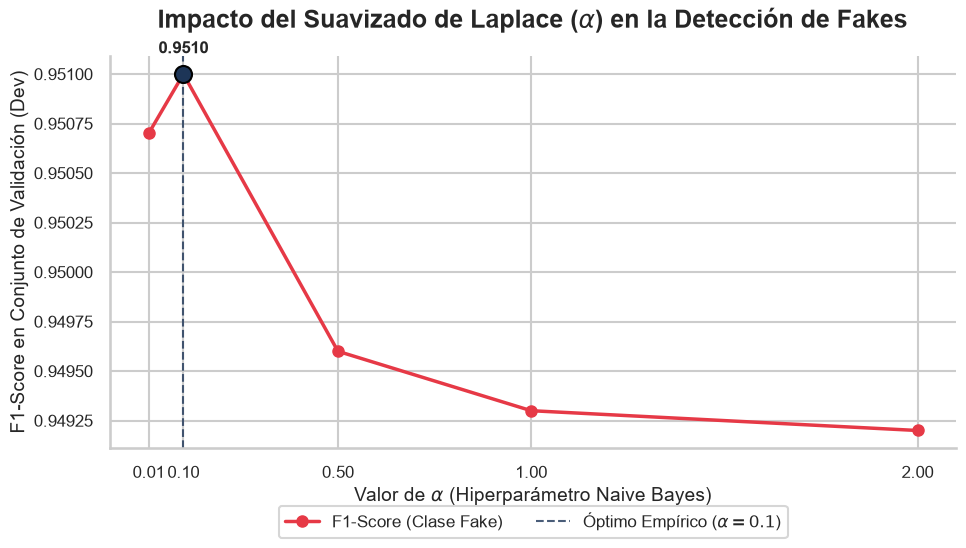

In [16]:
#@title suavizado alpha con dev
alphas = [0.01, 0.1, 0.5, 1, 2]
resultados = []

for alpha in alphas:
    modelo = multinomialnb(alpha=alpha)
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_dev)
    prob = modelo.predict_proba(x_dev)[:, 1]
    fila = evaluar(y_dev, pred, prob)
    fila['alpha'] = alpha
    resultados.append(fila)

tabla_alpha = pd.DataFrame(resultados).set_index('alpha').round(4)
print(tabla_alpha)

mejor_alpha = tabla_alpha['f1'].idxmax()
print('\nmejor alpha según f1 de etiquetas Fake en dev:', mejor_alpha)

#Ploteo
#----
# 1. Configuración estética académica para la presentación
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(10, 6))

# Extracción de la métrica objetivo desde tu DataFrame iterado
eje_x = tabla_alpha.index
metrica_f1 = tabla_alpha['f1']

# 2. Generación del gráfico de líneas para la evolución del hiperparámetro
ax.plot(eje_x, metrica_f1, marker='o', markersize=8, linestyle='-', linewidth=2.5, 
        color='#E63946', label='F1-Score (Clase Fake)')

# 3. Marcado topológico del hiperparámetro óptimo
mejor_alpha = metrica_f1.idxmax()
mejor_f1 = metrica_f1.max()

# Trazado de una línea vertical de referencia (asíntota indicativa)
ax.axvline(x=mejor_alpha, color='#1D3557', linestyle='--', linewidth=1.5, alpha=0.8, 
           label=f'Óptimo Empírico ($\\alpha = {mejor_alpha}$)')

# Resaltar el punto exacto de maximización
ax.scatter(mejor_alpha, mejor_f1, color='#1D3557', s=150, zorder=5, edgecolor='black')
ax.annotate(f"{mejor_f1:.4f}", 
            (mejor_alpha, mejor_f1),
            textcoords="offset points", 
            xytext=(0, 15), 
            ha='center', 
            fontsize=12, 
            fontweight='bold')

# 4. Formateo de ejes y metadatos
ax.set_title('Impacto del Suavizado de Laplace ($\\alpha$) en la Detección de Fakes', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Valor de $\\alpha$ (Hiperparámetro Naive Bayes)', fontsize=14)
ax.set_ylabel('F1-Score en Conjunto de Validación (Dev)', fontsize=14)

# Asegurar que el eje X muestre los valores discretos exactos que probaste
ax.set_xticks(eje_x)
ax.tick_params(axis='both', labelsize=12)

ax.legend(loc='lower center', fontsize=12, bbox_to_anchor=(0.5, -0.25), ncol=2)

sns.despine()
plt.tight_layout()
plt.show()

In [17]:
#@title modelo casero de NB
class NaiveBayesMultinomial:
    """Bayes ingenuo multinomial manual, en log-espacio, sobre matriz dispersa."""
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    """ 
    Aqui ya entra una matriz spark
    1. Calculamos el logaritmo de la proporcion de documentos por clase sobre el total (log(probabilidad de clase))
    2. Hacemos el conteo de palabras totales por clase
    3. Aplicamos la matriz de verosimilitud (self.feature_log_prob_[k]) y guardamos los valores del logaritmo de la probabilidad de una palabra dado una clase en un vector 
    """
    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        V = X.shape[1]
        self.class_log_prior_ = np.zeros(len(self.classes_))
        self.feature_log_prob_ = np.zeros((len(self.classes_), V))
        for k, c in enumerate(self.classes_):
            Xc = X[y == c]
            self.class_log_prior_[k] = np.log(Xc.shape[0] / X.shape[0])   # log P(c)
            conteo_w = np.asarray(Xc.sum(axis=0)).ravel()                 # N(w, c)
            total = conteo_w.sum()                                        # N(c)
            # log P(w|c) con suavizado de Laplace
            self.feature_log_prob_[k] = np.log(conteo_w + self.alpha) - np.log(total + self.alpha * V)
        return self

    """
    Hacemos la multiplicacion matricial de obtener los valores en logaritmo de las probabilidades de ser de cada clase segun las palabras que contenga el texto
    Obtenemos: JLL= [valor clase 0, valor clase 1]
    """
    def _jll(self, X):
        # log P(c) + sum_w x_w * log P(w|c)
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    """
    Calculamos ahora si las probabilidades en porcentaje 
    la proporcion de las clases esta dada por el exponencial del JLL/la suma de los dos anteriores 
    """
    def predict_proba(self, X):
        jll = self._jll(X)
        jll = jll - jll.max(axis=1, keepdims=True)    # estabilidad numérica (log-sum-exp)
        p = np.exp(jll)
        return p / p.sum(axis=1, keepdims=True)
    
    """
    Dependiendo de las probabilidades anteriores mapeamos segun el argumento maximo sobre la matriz de log-verosimilitud determinando a que clase corresponde
    """
    def predict(self, X):
        return self.classes_[np.argmax(self._jll(X), axis=1)]


# Búsqueda de alpha en dev (igual que la celda 18, pero con el modelo manual)
resultados_m = []
for alpha in alphas:
    m = NaiveBayesMultinomial(alpha=alpha).fit(x_train, y_train)
    fila = evaluar(y_dev, m.predict(x_dev), m.predict_proba(x_dev)[:, 1])
    fila['alpha'] = alpha
    resultados_m.append(fila)
tabla_alpha_manual = pd.DataFrame(resultados_m).set_index('alpha').round(4)
print(tabla_alpha_manual)
mejor_alpha_manual = tabla_alpha_manual['f1'].idxmax()

# Modelo final manual en test
nb_manual = NaiveBayesMultinomial(alpha=mejor_alpha_manual).fit(x_train, y_train)
pred_m = nb_manual.predict(x_test)
prob_m = nb_manual.predict_proba(x_test)[:, 1]
metricas_manual = evaluar(y_test, pred_m, prob_m)


       exactitud  precision  exhaustividad      f1  auc_roc
alpha                                                      
0.01      0.9551     0.9436         0.9580  0.9507   0.9794
0.10      0.9555     0.9453         0.9569  0.9510   0.9794
0.50      0.9543     0.9452         0.9542  0.9496   0.9795
1.00      0.9539     0.9448         0.9538  0.9493   0.9796
2.00      0.9539     0.9451         0.9534  0.9492   0.9797


In [18]:
#@title modelo final y evaluación en test
nb = multinomialnb(alpha=mejor_alpha)
nb.fit(x_train, y_train)

pred_test = nb.predict(x_test)
prob_test = nb.predict_proba(x_test)[:, 1]

metricas_nb = evaluar(y_test, pred_test, prob_test)
print(pd.Series(metricas_nb).round(4))

cm = confusion_matrix(y_test, pred_test)
print(pd.DataFrame(cm, index=['real ham', 'real spam'],
                   columns=['pred ham', 'pred spam']))

print('\npiso de exactitud (predecir todo ham):', round(1 - y_test.mean(), 4))

exactitud        0.9517
precision        0.9441
exhaustividad    0.9492
f1               0.9467
auc_roc          0.9760
dtype: float64
           pred ham  pred spam
real ham       3032        147
real spam       133       2485

piso de exactitud (predecir todo ham): 0.5484


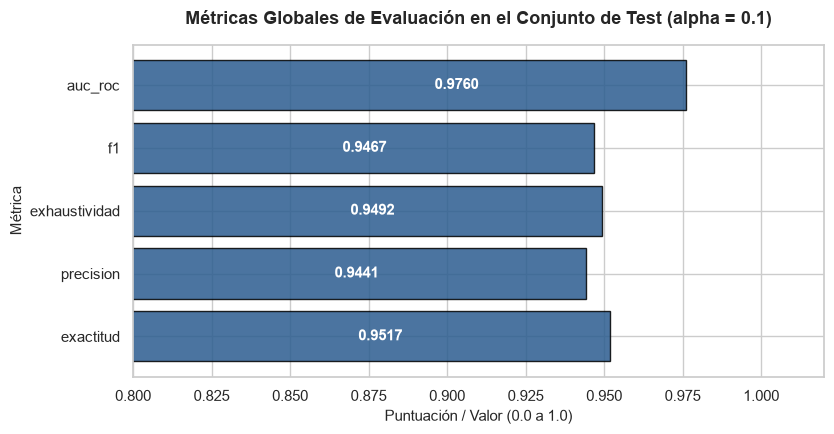

In [19]:
# Convertir las métricas de test a DataFrame
df_metricas = pd.Series(metricas_nb).reset_index()
df_metricas.columns = ['Métrica', 'Valor']

# Configuración visual
plt.figure(figsize=(8.5, 4.5))
sns.set_theme(style="whitegrid")

# Graficar barras horizontales
barras = plt.barh(df_metricas['Métrica'], df_metricas['Valor'], color='#2b5c8f', edgecolor='black', alpha=0.85)

# Agregar el valor numérico en texto dentro de cada barra
for barra in barras:
    ancho = barra.get_width()
    plt.text(
        ancho - 0.08,
        barra.get_y() + barra.get_height() / 2,
        f'{ancho:.4f}',
        va='center',
        ha='left',
        color='white',
        fontweight='bold',
        fontsize=11
    )

# Ajustar límites para enfocar la escala de desempeño (80% a 100%)
plt.xlim(0.80, 1.02)
plt.title('Métricas Globales de Evaluación en el Conjunto de Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
plt.ylabel('Métrica', fontsize=11)

plt.tight_layout()
plt.show()

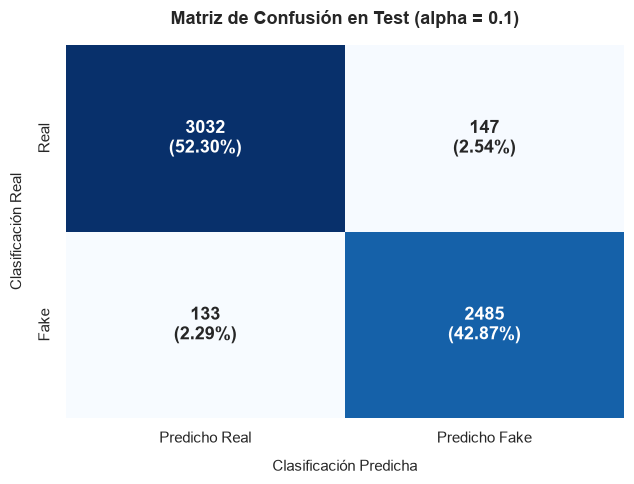

In [20]:
# Configuración visual
plt.figure(figsize=(6.5, 5))
sns.set_theme(style="white")

# Matriz de confusión con conteos y porcentajes
conteos = [f"{valor:d}" for valor in cm.flatten()]
porcentajes = [f"({valor:.2%})" for valor in cm.flatten() / np.sum(cm)]
etiquetas = np.array([f"{c}\n{p}" for c, p in zip(conteos, porcentajes)]).reshape(2, 2)

sns.heatmap(
    cm,
    annot=etiquetas,
    fmt='',
    cmap='Blues',
    cbar=False,
    xticklabels=['Predicho Real', 'Predicho Fake'],
    yticklabels=['Real', 'Fake'],
    annot_kws={"size": 13, "weight": "bold"}
)

# Título corregido sin secuencias de escape no procesadas
plt.title('Matriz de Confusión en Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Clasificación Predicha', fontsize=11, labelpad=10)
plt.ylabel('Clasificación Real', fontsize=11, labelpad=10)

plt.tight_layout()
plt.show()


findfont: Failed to find font weight medium for Arial, now using 400.


                sklearn    manual  diferencia
exactitud      0.951699  0.951699    0.000000
precision      0.944149  0.944149    0.000000
exhaustividad  0.949198  0.949198    0.000000
f1             0.946667  0.946667    0.000000
auc_roc        0.975999  0.976777    0.000779
mismas predicciones: True
max |dif| en probabilidades: 7.009948177483238e-13
max |dif| en log P(w|c): 0.0


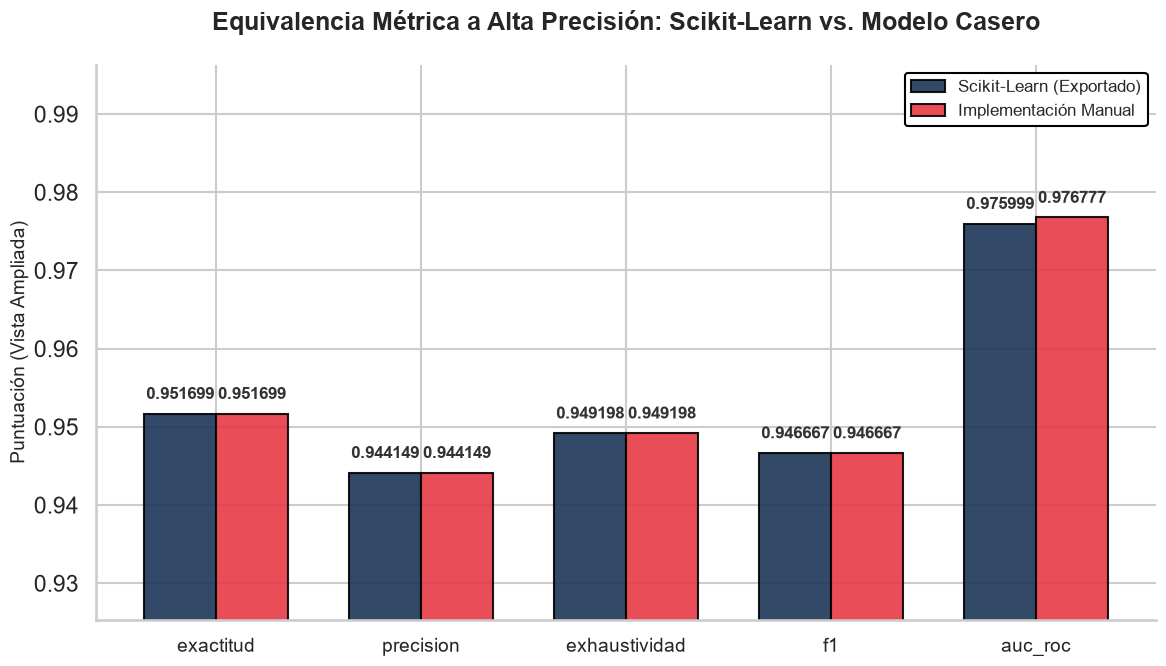

In [21]:
comparacion = pd.DataFrame({
    'sklearn': metricas_nb,
    'manual': metricas_manual
})
comparacion['diferencia'] = comparacion['manual'] - comparacion['sklearn']
print(comparacion.round(6))

print('mismas predicciones:', (pred_m == pred_test).all())
print('max |dif| en probabilidades:', np.abs(prob_m - prob_test).max())
print('max |dif| en log P(w|c):', np.abs(nb_manual.feature_log_prob_ - nb.feature_log_prob_).max())

#Ploteo 
#----
# 1. Configuración estética académica
# 1. Configuración estética para la presentación
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(12, 7))

# Definición de los ejes y anchura de barras
x = np.arange(len(comparacion.index))
width = 0.35

# Colores de alto contraste
color_sklearn = '#1D3557' # Azul oscuro institucional
color_manual = '#E63946'  # Rojo vibrante

# 2. Generación de las barras agrupadas
barras_sk = ax.bar(x - width/2, comparacion['sklearn'], width, 
                   label='Scikit-Learn (Exportado)', color=color_sklearn, edgecolor='black', alpha=0.9)
barras_mn = ax.bar(x + width/2, comparacion['manual'], width, 
                   label='Implementación Manual', color=color_manual, edgecolor='black', alpha=0.9)

# 3. Recorte topológico (Zoom Dinámico)
# Calculamos el valor mínimo y máximo de todas las métricas para enfocar el eje Y solo en la varianza
min_val = comparacion[['sklearn', 'manual']].min().min()
max_val = comparacion[['sklearn', 'manual']].max().max()

# Ajustamos el límite inferior ligeramente por debajo del mínimo para no cortar las barras
ax.set_ylim(min_val * 0.98, max_val * 1.02)

# 4. Función para inyectar precisión de 6 decimales en las etiquetas
def anotar_precision(barras):
    for barra in barras:
        altura = barra.get_height()
        # El formato .6f garantiza que se expongan los residuos computacionales
        ax.annotate(f'{altura:.6f}',
                    xy=(barra.get_x() + barra.get_width() / 2, altura),
                    xytext=(0, 8),  # Desplazamiento vertical en puntos
                    textcoords="offset points",
                    ha='center', va='bottom', 
                    fontsize=12, fontweight='bold', color='#333333', rotation=0)

anotar_precision(barras_sk)
anotar_precision(barras_mn)

# 5. Formateo y metadatos
ax.set_title('Equivalencia Métrica a Alta Precisión: Scikit-Learn vs. Modelo Casero', 
             fontsize=18, fontweight='bold', pad=25)
ax.set_ylabel('Puntuación (Vista Ampliada)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(comparacion.index, fontsize=14, fontweight='medium')

# Ubicación de la leyenda fuera de las barras para evitar obstrucciones visuales
ax.legend(loc='upper right', fontsize=12, framealpha=1, edgecolor='black')

# Optimización espacial
sns.despine()
plt.tight_layout()
plt.show()

## Experimentos control e interpretación de los resultados


### Experimento de control de la representación

Comprobar si los resultados son razonables y si existe evidencia de que el modelo aprendió asociaciones útiles.



In [22]:
#@title palabras con mayor log-razón
#El propósito de esta celda es identificar las palabras que más favorecen estadísticamente a cada clase según el modelo Naive Bayes entrenado
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

#solo palabras con al menos 5 apariciones en train ( y las raras dan valores extremos por azar)
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:15]
mas_ham = orden[:15]

print('palabras más asociadas a spam')
print(pd.DataFrame({'palabra': vocab[mas_spam], 'log_razon': log_razon[mas_spam].round(3),'frecuencia': frec_train[mas_spam]}).to_string(index=False))

print('\npalabras más asociadas a ham')
print(pd.DataFrame({'palabra': vocab[mas_ham], 'log_razon': log_razon[mas_ham].round(3),'frecuencia': frec_train[mas_ham]}).to_string(index=False))

palabras más asociadas a spam
     palabra  log_razon  frecuencia
       https     10.181        2435
      21wire      9.009         754
          js      8.840         637
        quot      8.750         582
      flickr      8.395         408
 somodevilla      8.189         332
     2017the      8.161         323
         fjs      8.136         315
       getty      7.946        2867
         var      7.864         240
         acr      7.856         238
       cdata      7.795         224
filessupport      7.745         213
     mcnamee      7.682         200
   2017trump      7.657         195

palabras más asociadas a ham
   palabra  log_razon  frecuencia
   myanmar     -9.765        1888
  rohingya     -9.489        1432
   rakhine     -8.559         565
      zuma     -8.351         459
puigdemont     -8.336         452
       fdp     -8.136         370
       suu     -8.054         341
       kyi     -8.054         341
       anc     -7.933         302
 mnangagwa     -7.871   

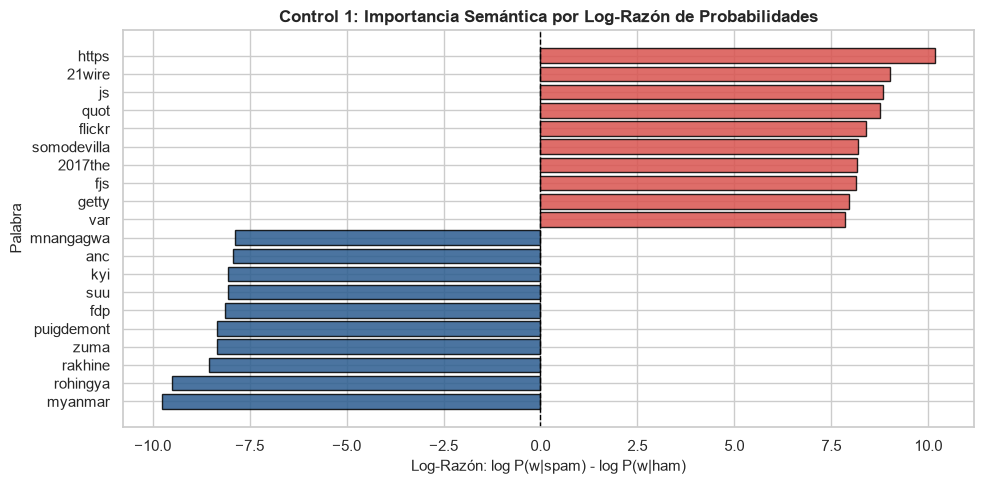

In [23]:
# Estilo visual
sns.set_theme(style="whitegrid")

# Extracción de términos y log-razón del modelo Bayes Ingenuo (nb)
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

# Filtrar palabras con al menos 5 apariciones
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:10]
mas_ham = orden[:10]

palabras = np.concatenate([vocab[mas_ham], vocab[mas_spam][::-1]])
valores = np.concatenate([log_razon[mas_ham], log_razon[mas_spam][::-1]])

# Crear DataFrame para graficar
df_palabras = pd.DataFrame({'palabra': palabras, 'log_razon': valores})

fig, ax = plt.subplots(figsize=(10, 5))
colores = ['#2b5c8f' if v < 0 else '#d9534f' for v in df_palabras['log_razon']]

ax.barh(df_palabras['palabra'], df_palabras['log_razon'], color=colores, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

ax.set_title('Control 1: Importancia Semántica por Log-Razón de Probabilidades', fontsize=12, fontweight='bold')
ax.set_xlabel('Log-Razón: log P(w|spam) - log P(w|ham)', fontsize=11)
ax.set_ylabel('Palabra', fontsize=11)

plt.tight_layout()
plt.show()


In [24]:
#@title varias permutaciones
# Se mezclan aleatoriamente las etiquetas de Train, manteniendo los mismos mensajes y el mismo número de etiquetas de cada clase.
n_perm = 30
resultados_perm = []

for i in range(n_perm):
    rng_i = np.random.default_rng(seed + i)
    y_perm_i = rng_i.permutation(y_train.values)
    nb_i = multinomialnb(alpha=mejor_alpha).fit(x_train, y_perm_i)
    resultados_perm.append(evaluar(y_test, nb_i.predict(x_test),
                                   nb_i.predict_proba(x_test)[:, 1]))

tabla_perm = pd.DataFrame(resultados_perm)
resumen_perm = pd.DataFrame({
    'etiquetas reales': metricas_nb,
    'permutadas (media)': tabla_perm.mean(),
    'permutadas (desv. est.)': tabla_perm.std()
}).round(4)
print(resumen_perm)

               etiquetas reales  permutadas (media)  permutadas (desv. est.)
exactitud                0.9517              0.5108                   0.0539
precision                0.9441              0.4573                   0.0616
exhaustividad            0.9492              0.4463                   0.0637
f1                       0.9467              0.4515                   0.0619
auc_roc                  0.9760              0.5040                   0.0641


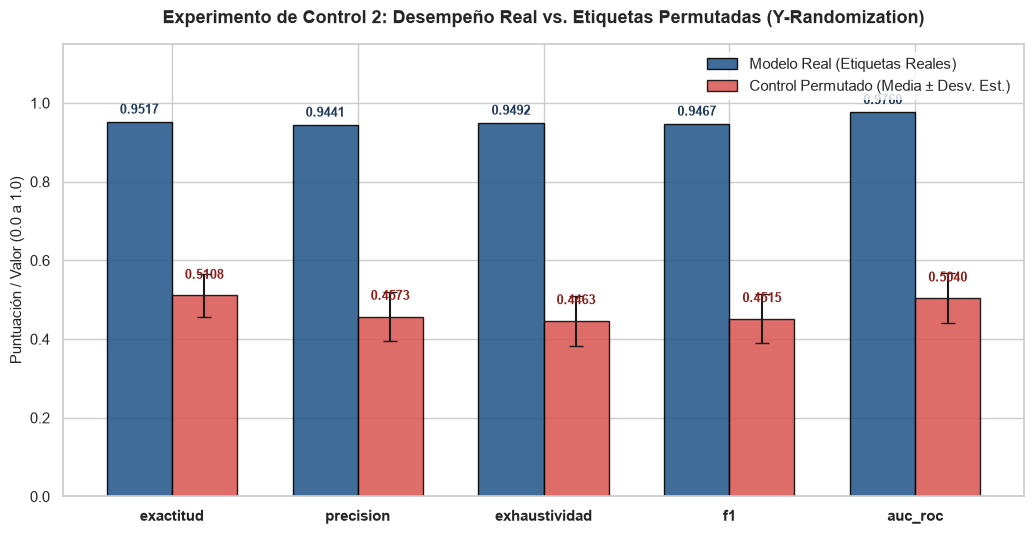

In [25]:
# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# Extraer los datos del DataFrame resumen_perm
metricas = resumen_perm.index
reales = resumen_perm['etiquetas reales']
perm_media = resumen_perm['permutadas (media)']
perm_std = resumen_perm['permutadas (desv. est.)']

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10.5, 5.5))

# Barras para el modelo con etiquetas reales
rects1 = ax.bar(
    x - ancho/2,
    reales,
    ancho,
    label='Modelo Real (Etiquetas Reales)',
    color='#2b5c8f',
    edgecolor='black',
    alpha=0.9
)

# Barras para el experimento de control (permutadas) con barras de error
rects2 = ax.bar(
    x + ancho/2,
    perm_media,
    ancho,
    yerr=perm_std,
    capsize=5,
    label='Control Permutado (Media ± Desv. Est.)',
    color='#d9534f',
    edgecolor='black',
    alpha=0.85
)

# Etiquetas numéricas sobre cada barra
for rect in rects1:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1f3a58'
    )

for rect in rects2:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 10),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#8c1d18'
    )

# Formato de ejes y leyendas
ax.set_ylabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
ax.set_title('Experimento de Control 2: Desempeño Real vs. Etiquetas Permutadas (Y-Randomization)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

### Interpretación del experimento control y métricas

Para esta primera etapa, llevamos a cabo un análisis integral del corpus de noticias falsas (*Fake*) y verdaderas (*Real*), desde la exploración y preparación de los datos hasta la evaluación de nuestro modelo de referencia (*baseline*). Inicialmente, analizamos la distribución de las clases para determinar si existía un desbalance significativo. Los resultados mostraron una distribución relativamente equilibrada, con aproximadamente un 45.16 % de noticias falsas y un 54.84 % de noticias verdaderas antes de la partición experimental. Posteriormente, identificamos y eliminamos los registros cuyo contenido textual era exactamente igual, conservando una sola aparición de cada texto para reducir la redundancia del corpus. Después de esta depuración, el conjunto quedó conformado por 38,646 registros.

Como parte de la exploración del corpus, comparamos las longitudes de las noticias en caracteres y palabras. Observamos que las noticias falsas presentaban, en promedio, una mayor longitud: aproximadamente 2,550 caracteres y 425 palabras, frente a 2,379 caracteres y 385 palabras en las noticias verdaderas. Sin embargo, las distribuciones presentan solapamiento, por lo que la longitud, por sí sola, no permite distinguir de manera fiable ambas clases.

Posteriormente, garantizamos una partición estratificada de los conjuntos de Entrenamiento (*Train*), Validación (*Dev*) y Prueba (*Test*), utilizando una proporción de 70/15/15 y una semilla fija para preservar la reproducibilidad experimental. Esta estrategia permitió mantener proporciones similares de noticias falsas y verdaderas en las tres particiones. La representación textual se realizó mediante *Bag of Words* (Bolsa de Palabras), utilizando `CountVectorizer` para convertir los textos en una matriz dispersa de frecuencias de tokens. El vocabulario se aprendió exclusivamente a partir de Train, mientras que Dev y Test se transformaron utilizando ese mismo vocabulario, evitando la filtración de información durante la construcción de la representación.

A continuación, entrenamos un clasificador Multinomial Naive Bayes y seleccionamos el hiperparámetro de suavizado de Laplace (\(\alpha\)) mediante la evaluación de distintas alternativas en Dev. El valor seleccionado fue \(\alpha = 0.1\), al obtener el mayor F1-Score para la clase Fake entre los valores evaluados. Finalmente, evaluamos el modelo seleccionado sobre Test, un conjunto que permaneció aislado durante la selección del hiperparámetro, para estimar su capacidad de generalización.

#### **Rendimiento del modelo base**

Los resultados obtenidos en Test fueron los siguientes:

- **Exactitud (Accuracy):** 0.9517
- **Precisión (Precision):** 0.9441
- **Exhaustividad (Recall):** 0.9492
- **F1-Score:** 0.9467
- **AUC-ROC:** 0.9760

Estas métricas reflejan un rendimiento elevado y relativamente equilibrado en la identificación de noticias falsas y verdaderas. La exactitud indica que el modelo clasificó correctamente aproximadamente el 95.17 % de las noticias de Test. Por su parte, el F1-Score de 0.9467 muestra un buen equilibrio entre la precisión y la exhaustividad para la clase Fake, mientras que el AUC-ROC de 0.9760 indica una alta capacidad para ordenar correctamente ejemplos de ambas clases según su puntuación predictiva.

La matriz de confusión permite examinar con mayor detalle los errores cometidos. De las 5,797 noticias evaluadas, el modelo clasificó correctamente 3,032 noticias verdaderas y 2,485 noticias falsas. Los errores se distribuyeron en 147 falsos positivos (*noticias verdaderas clasificadas como falsas*) y 133 falsos negativos (*noticias falsas clasificadas como verdaderas*). Estos valores representan, respectivamente, el 2.54 % y el 2.29 % del conjunto de prueba.

Por tanto, el modelo no solo presenta una exactitud elevada, sino que mantiene una tasa de error reducida en ambas clases. Este comportamiento constituye una referencia sólida para la comparación posterior con la regresión logística. No obstante, las métricas por sí solas no permiten determinar qué señales lingüísticas explican el rendimiento ni demostrar que el modelo esté aprendiendo la veracidad de las afirmaciones; para ello, es necesario examinar la representación y los controles experimentales.

#### **Control de implementación: Naive Bayes manual frente a Scikit-learn**

Para comprobar que el rendimiento observado no dependía exclusivamente de la implementación proporcionada por Scikit-learn, desarrollamos una versión manual de Multinomial Naive Bayes. Esta implementación calcula las probabilidades condicionales de los tokens y realiza las operaciones en el espacio logarítmico, siguiendo la misma formulación probabilística del modelo utilizado por la biblioteca.

La comparación mostró que ambas implementaciones produjeron exactamente las mismas predicciones en Test, así como las mismas métricas de exactitud, precisión, exhaustividad y F1-Score. La diferencia observada en AUC-ROC fue muy pequeña: 0.9760 en Scikit-learn frente a aproximadamente 0.9768 en la implementación manual. En consecuencia, el control respalda que el rendimiento obtenido no es un efecto exclusivo de utilizar el framework, sino que es consistente con la formulación del clasificador implementada manualmente.

#### **Control de interpretabilidad: asociaciones léxicas por log-razón**

Para investigar qué características del vocabulario podían explicar el rendimiento del modelo, analizamos las asociaciones estadísticas entre los tokens y las clases mediante la diferencia entre sus log-probabilidades condicionales:

$L(w)=\log P(w\mid Fake)-\log P(w\mid Real)$

Los valores positivos indican que un token es relativamente más probable en las noticias falsas, mientras que los valores negativos indican una asociación más fuerte con las noticias verdaderas. Para reducir la influencia de términos extremadamente raros, el análisis consideró únicamente tokens con al menos cinco apariciones en el conjunto de entrenamiento.

Los resultados mostraron asociaciones de magnitud considerable en ambas direcciones. Entre los tokens asociados con Fake aparecieron `https`, `21wire`, `js`, `quot`, `flickr` y `getty`, mientras que entre los asociados con Real destacaron `myanmar`, `rohingya`, `rakhine`, `zuma` y `puigdemont`. Algunos términos alcanzaron valores de log-razón superiores a +10 o inferiores a −10 en el vocabulario analizado, lo que evidencia diferencias marcadas entre las probabilidades estimadas para las dos clases.

Estos resultados ofrecen una posible explicación del elevado rendimiento del baseline: cuando una noticia contiene tokens fuertemente asociados a una clase, sus frecuencias pueden contribuir considerablemente a la puntuación calculada por Naive Bayes. El modelo no necesita comprender semánticamente una noticia para aprovechar estas regularidades estadísticas.

Además, la exploración del vocabulario mostró que ambas clases comparten una cantidad considerable de tokens, pero también presentan términos exclusivos y diferencias en sus frecuencias relativas. Por ello, la capacidad discriminativa no depende exclusivamente de que una palabra aparezca en una sola clase, sino también de cuánto difiere su distribución entre Fake y Real.

Es importante destacar que algunos de los términos más discriminativos parecen corresponder a nombres propios, dominios, referencias a imágenes o fragmentos de formato. Esto plantea la hipótesis de que el modelo podría estar aprovechando parcialmente diferencias en las fuentes, los temas o la estructura editorial de las noticias. Por tanto, las asociaciones encontradas son evidencia de patrones predictivos en el corpus, pero no demuestran por sí solas que el modelo haya aprendido a determinar la veracidad factual de una noticia.

#### **Control mediante permutación de etiquetas: prueba de robustez**

Para comprobar si el rendimiento dependía de la relación entre el texto y las etiquetas originales, realizamos 30 experimentos de control mediante permutación de las etiquetas de Train. En cada repetición se mantuvieron los mismos textos y la misma representación numérica, pero se reasignaron aleatoriamente las etiquetas de entrenamiento. Posteriormente, se entrenó el clasificador con esas etiquetas permutadas y se evaluó sobre el conjunto Test original, conservando sus etiquetas reales.

Los resultados mostraron una reducción considerable del rendimiento:

- **F1-Score:** disminuyó de 0.9467 a una media de 0.4515, con una desviación estándar de 0.0619.
- **AUC-ROC:** pasó de 0.9760 a una media de 0.5040, con una desviación estándar de 0.0641.
- **Exactitud:** descendió de 0.9517 a una media de 0.5108, con una desviación estándar de 0.0539.

El AUC-ROC medio de 0.5040 se encuentra muy cerca de 0.50, el valor de referencia asociado a una capacidad de discriminación equivalente al azar. Asimismo, la caída del F1-Score evidencia que, al destruir la correspondencia entre los textos y sus etiquetas durante el entrenamiento, el modelo pierde gran parte de su capacidad para identificar correctamente la clase Fake.

Este comportamiento respalda que el rendimiento del modelo original depende de asociaciones aprendidas entre las características textuales y las etiquetas, y no únicamente de la estructura de la matriz o de la implementación del algoritmo. Sin embargo, la permutación no permite establecer si esas asociaciones representan características semánticas generalizables o patrones específicos del corpus; esa distinción deberá investigarse mediante controles adicionales de representación.

#### **Conclusión de la Etapa 1**

El clasificador Multinomial Naive Bayes constituye una referencia experimental sólida para las siguientes etapas del proyecto. Con una exactitud de 0.9517, un F1-Score de 0.9467 y un AUC-ROC de 0.9760, el modelo demuestra una capacidad elevada para distinguir entre noticias falsas y verdaderas dentro del conjunto de datos evaluado. La matriz de confusión confirma que los errores se mantienen por debajo del 3 % del total de ejemplos para cada uno de los dos tipos de equivocación considerados.

La comparación entre la implementación manual y Scikit-learn respalda la consistencia del resultado, mientras que el análisis de log-razones identifica tokens con asociaciones estadísticas muy marcadas con cada clase. Finalmente, los experimentos de permutación muestran que, al destruir la relación entre el texto y las etiquetas de entrenamiento, el rendimiento cae hasta valores próximos al azar en AUC-ROC.

En conjunto, estos resultados indican que el modelo está aprovechando regularidades léxicas presentes en el corpus para realizar sus predicciones. La elevada capacidad predictiva constituye una buena base para la comparación con regresión logística, pero también plantea una cuestión relevante: determinar hasta qué punto el rendimiento depende de señales lingüísticas generalizables o de características particulares de las fuentes, los temas y el formato de las noticias. Esta cuestión orientará los siguientes experimentos, en los que se estudiará si una representación alternativa y un modelo discriminativo pueden mantener o mejorar el rendimiento bajo las mismas condiciones de evaluación.

# Etapa 2: Primera Aproximación

## TF - IDF

### Representación de Texto mediante TF-IDF

En esta etapa reemplazamos el conteo simple de palabras (`CountVectorizer`) por la ponderación **TF-IDF** (Term Frequency - Inverse Document Frequency), como se recomienda en *Manning & Schütze (Foundations of Statistical NLP)*.

#### Formulación matemática
El peso $w_{t,d}$ del término $t$ en el documento $d$ se calcula como:
$$w_{t,d} = \text{tf}_{t,d} \times \text{idf}_t$$

Donde:
1. **Frecuencia Sublineal del Término ($\text{tf}_{t,d}$):**
   $$\text{tf}_{t,d} = 1 + \log(\text{count}(t,d)) \quad \text{si } \text{count}(t,d) > 0 \text{ (de lo contrario 0)}$$
   *Justificación:* Que una palabra aparezca 20 veces en un documento no significa que sea 20 veces más relevante que si aparece 1 vez. La escala logarítmica atenúa el impacto de frecuencias muy altas.

2. **Frecuencia Inversa de Documento ($\text{idf}_t$ con suavizado):**
   $$\text{idf}_t = \log \left( \frac{1 + N}{1 + \text{df}_t} \right) + 1$$
   Donde $N$ es el número total de documentos y $\text{df}_t$ es el número de documentos que contienen el término $t$.

#### ¿Por qué no usar solo `CountVectorizer`?
`CountVectorizer` asigna una ponderación proporcional al conteo crudo. Esto otorga demasiado peso a palabras muy frecuentes o funcionales (como *"the"*, *"to"*, *"and"*), las cuales aparecen constantemente pero no aportan poder discriminativo entre clases. **TF-IDF penaliza los términos que aparecen en muchos documentos** ($\text{df}_t$ grande $\Rightarrow \text{idf}_t$ pequeño), resaltando aquellas palabras descriptivas y distintivas del contenido.

In [26]:
# @title Transformación del corpus con TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Configuración basada en Manning & Schütze y limpieza de corpus
tfidf_vec = TfidfVectorizer(
    lowercase=True,
    stop_words='english',  # Filtra stopwords explícitas
    min_df=5,              # Ignora términos raros/ruido (< 5 documentos)
    max_df=0.8,            # Ignora términos que están en > 80% de docs (stopwords implícitas)
    ngram_range=(1, 1),    # Unigramas para la primera aproximación
    smooth_idf=True,       # Evita división entre cero (+1 en Manning)
    sublinear_tf=True      # Aplica tf = 1 + log(tf)
)

# Ajuste del vocabulario e IDF SOLO con Train para evitar data leakage
x_train_tfidf = tfidf_vec.fit_transform(x_train_txt)
x_dev_tfidf = tfidf_vec.transform(x_dev_txt)
x_test_tfidf = tfidf_vec.transform(x_test_txt)

print("Tamaño del vocabulario TF-IDF (Train):", x_train_tfidf.shape[1])
print("Dimensión de la matriz x_train_tfidf:", x_train_tfidf.shape)

Tamaño del vocabulario TF-IDF (Train): 31213
Dimensión de la matriz x_train_tfidf: (27052, 31213)


## Regresión Logística
Esta debera estar regularizada con L2

### Clasificación Discriminativa: Regresión Logística (Máxima Entropía) y Regularización $L_2$

En esta etapa sustituimos el modelo generativo de Bayes Ingenuo por un modelo **discriminativo**: la **Regresión Logística** (equivalente al enfoque de *Máxima Entropía* en procesamiento de lenguaje natural).

#### 1. Enfoque Discriminativo vs. Generativo
* **Bayes Ingenuo (Generativo):** Modela la distribución conjunta $P(X, Y) = P(X \mid Y)P(Y)$ asumiendo independencia condicional entre términos dado la clase.
* **Regresión Logística (Discriminativo):** Modela directamente la probabilidad condicional $P(Y = 1 \mid X)$ mediante la función sigmoide:
  $$P(Y = 1 \mid X) = \sigma(W^T X + b) = \frac{1}{1 + e^{-(W^T X + b)}}$$
  donde $W = [w_1, w_2, \dots, w_V]$ representa el vector de pesos asociados a cada término del vocabulario ($V = 31,213$ en nuestro espacio vectorial TF-IDF).

#### 2. Necesidad de la Regularización $L_2$
Dada la alta dimensionalidad del espacio de características ($31,213$ variables), los modelos lineales corren el riesgo de memorizar ruido del conjunto de entrenamiento (**sobreajuste** o *overfitting*), asignando pesos excesivamente grandes a palabras raras.

Para mitigar esto, aplicamos **regularización $L_2$ (Ridge)**, la cual modifica la función de costo agregando una penalización sobre la magnitud al cuadrado de los coeficientes:
$$\text{Costo}_{L2} = \text{Pérdida Logística} + \lambda \sum_{i=1}^V w_i^2$$

#### 3. El Hiperparámetro $C$ en Scikit-Learn
En la librería `scikit-learn`, la fuerza de la regularización se controla mediante el parámetro **$C$**, definido como el inverso del coeficiente de penalización:
$$C = \frac{1}{\lambda}$$

* **$C$ pequeño (ej. 0.01, 0.1):** Representa una **regularización fuerte** ($\lambda$ grande). Penaliza severamente los pesos grandes, comprimiéndolos hacia cero para reducir la varianza del modelo y evitar sobreajuste.
* **$C$ grande (ej. 10.0, 100.0):** Representa una **regularización débil** ($\lambda$ pequeño). Da mayor libertad al modelo para ajustar los datos de entrenamiento, corriendose el riesgo de sobreajuste si la complejidad es muy alta.

c:\Users\kevin\OneDrive\Escritorio\Licenciatura en Inteligencia Artificial\Notebooks\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kevin\OneDrive\Escritorio\Licenciatura en Inteligencia Artificial\Notebooks\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticn

Evaluación de Regresión Logística (L2) en conjunto dev
        exactitud  precision  exhaustividad      f1  auc_roc
C                                                           
0.01       0.9284     0.9850         0.8545  0.9152   0.9903
0.10       0.9729     0.9809         0.9588  0.9697   0.9958
1.00       0.9865     0.9904         0.9798  0.9850   0.9985
10.00      0.9907     0.9938         0.9855  0.9896   0.9992
100.00     0.9919     0.9946         0.9874  0.9910   0.9994

Mejor valor de C según F1 en dev: f1    100.0
dtype: float64


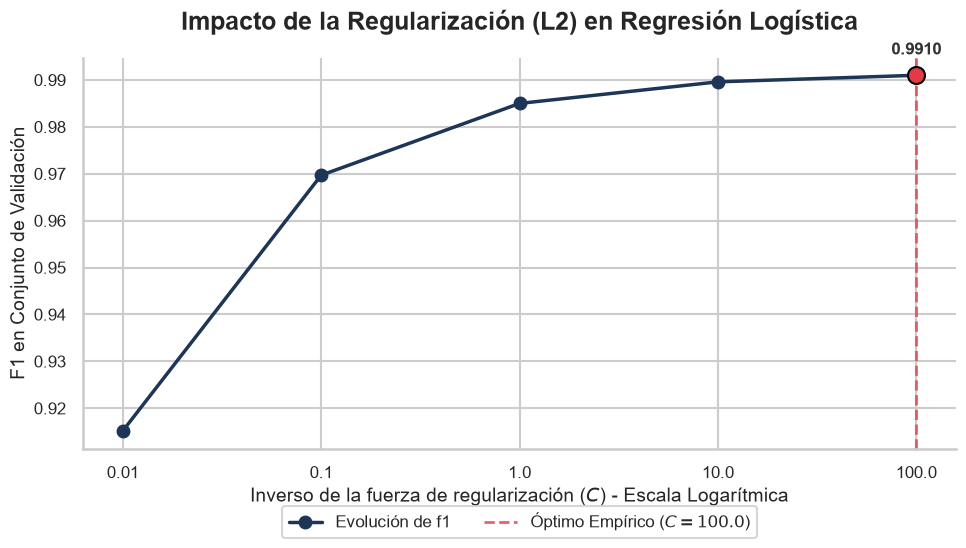

In [27]:
# @title Entrenamiento de Regresión Logística con L2 y ajuste de C en Dev
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Valores del hiperparámetro C a evaluar
c_values = [0.01, 0.1, 1.0, 10.0, 100.0]
resultados_logreg = []

for c in c_values:
    # Instanciar el modelo con penalización L2
    logreg = LogisticRegression(
        penalty='l2',
        C=c,
        solver='liblinear',  # Eficiente para matrices dispersas de texto
        random_state=seed,
        max_iter=1000
    )

    # Entrenar solo con el conjunto de Train
    logreg.fit(x_train_tfidf, y_train)

    # Evaluar en Dev
    pred_dev = logreg.predict(x_dev_tfidf)
    prob_dev = logreg.predict_proba(x_dev_tfidf)[:, 1]

    # Calcular métricas con la función de la Etapa 1
    res = evaluar(y_dev, pred_dev, prob_dev)
    res['C'] = c
    resultados_logreg.append(res)

# Mostrar la tabla de resultados en Dev
tabla_c = pd.DataFrame(resultados_logreg).set_index('C').round(4)
print("Evaluación de Regresión Logística (L2) en conjunto dev")
print(tabla_c)

# Seleccionar el mejor C según F1-score
col_f1 = 'f1_spam' if 'f1_spam' in tabla_c.columns else [c for c in tabla_c.columns if 'f1' in c]
mejor_c = tabla_c[col_f1].idxmax()
print(f"\nMejor valor de C según F1 en dev: {mejor_c}")

#Ploteo
#--------
# 1. Configuración estética académica
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(10, 6))

# Identificar dinámicamente la columna objetivo (F1)
col_f1 = [col for col in tabla_c.columns if 'f1' in col.lower()][0]
eje_x = tabla_c.index
metrica_f1 = tabla_c[col_f1]

# 2. Generación del gráfico de líneas
ax.plot(eje_x, metrica_f1, marker='o', markersize=9, linestyle='-', linewidth=2.5, 
        color='#1D3557', label=f'Evolución de {col_f1}')

# 3. Transformación topológica del eje X a escala logarítmica (CRÍTICO)
ax.set_xscale('log')

# 4. Marcado topológico del hiperparámetro óptimo
mejor_c = metrica_f1.idxmax()
mejor_f1 = metrica_f1.max()

# Trazado de la asíntota de referencia para el óptimo
ax.axvline(x=mejor_c, color='#E63946', linestyle='--', linewidth=2, alpha=0.8, 
           label=f'Óptimo Empírico ($C = {mejor_c}$)')

# Resaltar el punto exacto de maximización
ax.scatter(mejor_c, mejor_f1, color='#E63946', s=150, zorder=5, edgecolor='black')
ax.annotate(f"{mejor_f1:.4f}", 
            (mejor_c, mejor_f1),
            textcoords="offset points", 
            xytext=(0, 15), 
            ha='center', 
            fontsize=12, 
            fontweight='bold',
            color='#333333')

# 5. Formateo de ejes y metadatos
ax.set_title('Impacto de la Regularización (L2) en Regresión Logística', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Inverso de la fuerza de regularización ($C$) - Escala Logarítmica', fontsize=14)
ax.set_ylabel(f'{col_f1.capitalize()} en Conjunto de Validación', fontsize=14)

# Forzar explícitamente las etiquetas del eje X para mostrar tus valores exactos
ax.set_xticks(eje_x)
ax.set_xticklabels(eje_x)
ax.tick_params(axis='both', labelsize=12)

# Optimización de la leyenda
ax.legend(loc='lower center', fontsize=12, bbox_to_anchor=(0.5, -0.25), ncol=2)

# Limpieza espacial
sns.despine()
plt.tight_layout()
plt.show()

## Comparar modelos

c:\Users\kevin\OneDrive\Escritorio\Licenciatura en Inteligencia Artificial\Notebooks\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


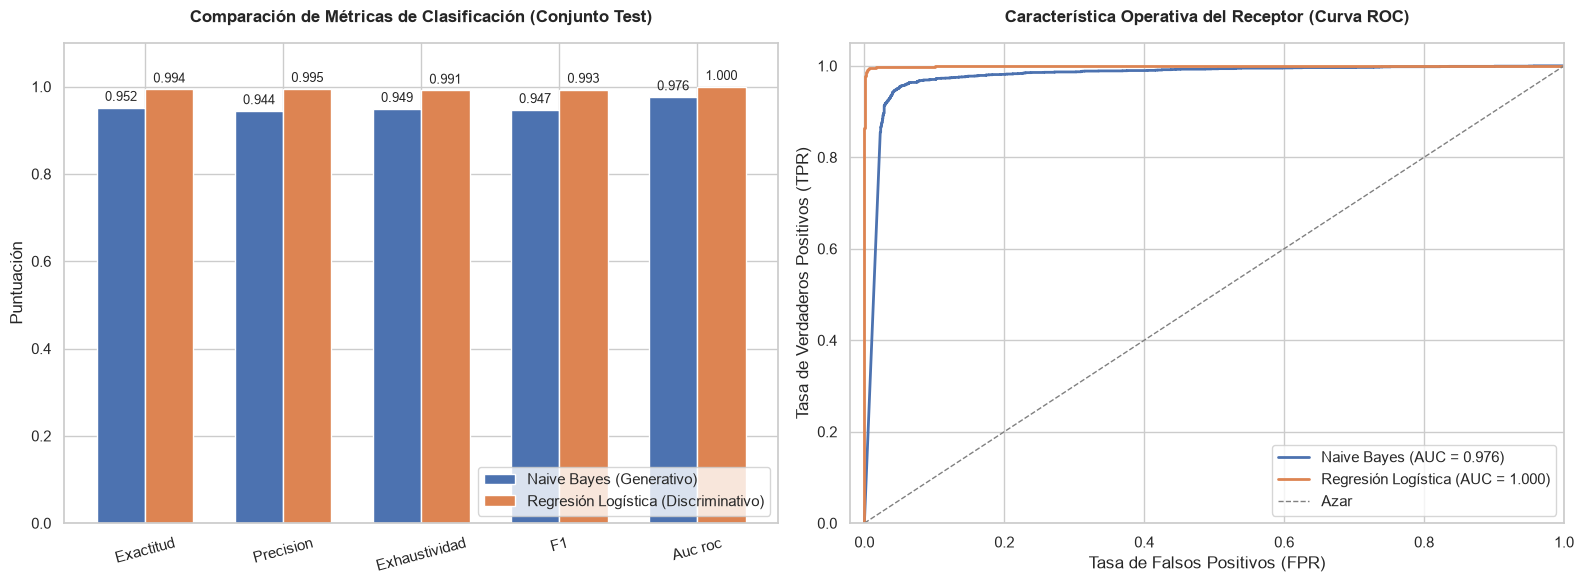

In [35]:
# ==============================================================================
# 1. EVALUACIÓN HOMOLOGADA EN EL CONJUNTO DE PRUEBA (TEST)
# ==============================================================================

# Instanciar el modelo final de Regresión Logística usando el mejor hiperparámetro
mejor_logreg = LogisticRegression(
    penalty='l2',
    C=mejor_c,
    solver='liblinear',
    random_state=seed, 
    max_iter=1000
)

# Ajustar el modelo final (asumiendo x_train_tfidf y y_train en memoria)
mejor_logreg.fit(x_train_tfidf, y_train)

# Generar predicciones de Regresión Logística sobre el conjunto TEST
# (Asumiendo que x_test_tfidf se generó con tfidf_vec.transform(x_test_txt))
pred_test_lr = mejor_logreg.predict(x_test_tfidf)
prob_test_lr = mejor_logreg.predict_proba(x_test_tfidf)[:, 1]

# Calcular métricas finales de LR con tu función personalizada
metricas_lr = evaluar(y_test, pred_test_lr, prob_test_lr)

# ==============================================================================
# 2. DEFINICIÓN DE LA FUNCIÓN DE VISUALIZACIÓN
# ==============================================================================

def plot_model_comparison(res_nb, res_lr, y_true, prob_nb, prob_lr):
    sns.set_theme(style="whitegrid", palette="muted")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=100)
    
    # --- Gráfico 1: Comparación de Métricas ---
    # Extraemos dinámicamente las llaves del diccionario de tu función 'evaluar'
    # Filtramos llaves que no sean métricas directas (ej. tiempos de ejecución si los hay)
    metricas_comunes = [k for k in res_nb.keys() if isinstance(res_nb[k], (int, float))]
    
    valores_nb = [res_nb[m] for m in metricas_comunes]
    valores_lr = [res_lr[m] for m in metricas_comunes]
    
    x = np.arange(len(metricas_comunes))
    width = 0.35
    
    rects1 = axes[0].bar(x - width/2, valores_nb, width, label='Naive Bayes (Generativo)', color='#4C72B0')
    rects2 = axes[0].bar(x + width/2, valores_lr, width, label='Regresión Logística (Discriminativo)', color='#DD8452')
    
    axes[0].set_ylabel('Puntuación')
    axes[0].set_title('Comparación de Métricas de Clasificación (Conjunto Test)', pad=15, fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([str(m).replace('_', ' ').capitalize() for m in metricas_comunes], rotation=15)
    axes[0].set_ylim(0, 1.1)
    axes[0].legend(loc='lower right')
    
    # Anotaciones sobre las barras
    for rects in [rects1, rects2]:
        for rect in rects:
            height = rect.get_height()
            axes[0].annotate(f'{height:.3f}',
                             xy=(rect.get_x() + rect.get_width() / 2, height),
                             xytext=(0, 3),  
                             textcoords="offset points",
                             ha='center', va='bottom', fontsize=9)

    # --- Gráfico 2: Curvas ROC ---
    fpr_nb, tpr_nb, _ = roc_curve(y_true, prob_nb)
    roc_auc_nb = auc(fpr_nb, tpr_nb)
    
    fpr_lr, tpr_lr, _ = roc_curve(y_true, prob_lr)
    roc_auc_lr = auc(fpr_lr, tpr_lr)
    
    axes[1].plot(fpr_nb, tpr_nb, color='#4C72B0', lw=2, label=f'Naive Bayes (AUC = {roc_auc_nb:.3f})')
    axes[1].plot(fpr_lr, tpr_lr, color='#DD8452', lw=2, label=f'Regresión Logística (AUC = {roc_auc_lr:.3f})')
    axes[1].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Azar')
    
    axes[1].set_xlim([-0.02, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
    axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    axes[1].set_title('Característica Operativa del Receptor (Curva ROC)', pad=15, fontweight='bold')
    axes[1].legend(loc="lower right")
    
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. EJECUCIÓN DE LA VISUALIZACIÓN
# ==============================================================================
# Se inyectan las variables exactas provenientes de tus bloques de código y del paso 1
plot_model_comparison(metricas_nb, metricas_lr, y_test, prob_test, prob_test_lr)

## Efecto del umbral de decisión

# Etapa 3: Mejora

## Añadir atributos

## Ajustar el umbral 

# Conclusiones Finales